# Texas State Employee Salary — Data Analysis & Prediction
# By: Suchitra Thanumalayan

- **Task 1:** Data analysis report
- **Task 2:** Predictive model for employee salary
- **Task 3:** Questions on outliers, manager vs employee pay, and changes over time

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("salary.csv", low_memory=False)
df.head()

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN


# Task 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(149481, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149481 entries, 0 to 149480
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   AGENCY                   149481 non-null  int64  
 1   AGENCY NAME              149481 non-null  str    
 2   LAST NAME                149481 non-null  str    
 3   FIRST NAME               149481 non-null  str    
 4   MI                       149481 non-null  str    
 5   CLASS CODE               149481 non-null  str    
 6   CLASS TITLE              149481 non-null  str    
 7   ETHNICITY                149481 non-null  str    
 8   GENDER                   149481 non-null  str    
 9   STATUS                   149481 non-null  str    
 10  EMPLOY DATE              149481 non-null  str    
 11  HRLY RATE                149481 non-null  float64
 12  HRS PER WK               149481 non-null  float64
 13  MONTHLY                  149481 non-null  float64
 14  ANNUAL         

In [5]:
df.describe()

,AGENCY,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,multiple_full_time_jobs,summed_annual_salary
count,149481.000000,149481.000000,149481.000000,149481.000000,149481.000000,1.494810e+05,14.0,16.000000
mean,545.736288,0.346488,39.714918,4226.184248,50714.210973,5.651930e+05,1.0,74303.955000
std,139.057691,4.211485,2.323855,2093.111691,25117.340292,4.786212e+05,0.0,51925.944282
min,101.000000,0.000000,1.000000,50.000000,600.000000,1.000000e+00,1.0,18000.000000
25%,529.000000,0.000000,40.000000,3019.840000,36238.080000,1.133340e+05,1.0,32962.500000
50%,530.000000,0.000000,40.000000,3720.170000,44642.040000,3.463730e+05,1.0,48063.300000
75%,696.000000,0.000000,40.000000,4865.810000,58389.720000,1.100500e+06,1.0,123751.770000
max,930.000000,117.788480,70.000000,46125.000000,553500.000000,1.271604e+06,1.0,171383.400000


In [6]:
df.isnull().sum()

AGENCY                          0
AGENCY NAME                     0
LAST NAME                       0
FIRST NAME                      0
MI                              0
CLASS CODE                      0
CLASS TITLE                     0
ETHNICITY                       0
GENDER                          0
STATUS                          0
EMPLOY DATE                     0
HRLY RATE                       0
HRS PER WK                      0
MONTHLY                         0
ANNUAL                          0
STATE NUMBER                    0
duplicated                 149338
multiple_full_time_jobs    149467
combined_multiple_jobs     149384
summed_annual_salary       149465
hide_from_search           149465
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

AGENCY                        113
AGENCY NAME                   113
LAST NAME                   38675
FIRST NAME                  23559
MI                             27
CLASS CODE                   1481
CLASS TITLE                  1422
ETHNICITY                       6
GENDER                          2
STATUS                         11
EMPLOY DATE                  6295
HRLY RATE                     206
HRS PER WK                     58
MONTHLY                     40552
ANNUAL                      40554
STATE NUMBER               149465
duplicated                      1
multiple_full_time_jobs         1
combined_multiple_jobs          1
summed_annual_salary           15
hide_from_search                1
dtype: int64

**Observations**
- The last 5 columns (`duplicated`, `multiple_full_time_jobs`, `combined_multiple_jobs`, `summed_annual_salary`, `hide_from_search`) are almost completely empty (over 99.9% null).
- `LAST NAME`, `FIRST NAME`, `MI` and `STATE NUMBER` are personal identifiers, so they are not useful for analysis.
- `AGENCY` is just a code for `AGENCY NAME`, and `CLASS CODE` is a code for `CLASS TITLE`.
- `HRLY RATE` is 0 for almost every row.
- `MONTHLY` is just `ANNUAL / 12`.
- There are no duplicate rows.

## Cleaning The Data

In [9]:
# drop columns that are empty or not needed for the analysis
df = df.drop(columns=['duplicated', 'multiple_full_time_jobs', 'combined_multiple_jobs', 'summed_annual_salary',
                      'hide_from_search', 'LAST NAME', 'FIRST NAME', 'MI', 'STATE NUMBER', 'AGENCY',
                      'CLASS CODE', 'HRLY RATE'])

# remove extra spaces from the text columns
for col in ['AGENCY NAME', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS']:
    df[col] = df[col].str.strip()

df.head()

,AGENCY NAME,CLASS TITLE,ETHNICITY,GENDER,STATUS,EMPLOY DATE,HRS PER WK,MONTHLY,ANNUAL
0,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION","JUDGE, RETIRED",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,02/18/88,29.0,9545.82,114549.84
1,OFFICE OF COURT ADMINISTRATION,GENERAL COUNSEL IV,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,02/01/15,4.0,1404.77,16857.24
2,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION","JUDGE, RETIRED",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,02/01/20,29.0,9545.82,114549.84
3,OFFICE OF COURT ADMINISTRATION,GENERAL COUNSEL IV,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,09/01/18,4.0,1404.77,16857.24
4,TEXAS DEPARTMENT OF CRIMINAL JUSTICE,CORREC OFFICER IV,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,06/29/20,40.0,3284.27,39411.24


In [10]:
# convert the employ date into hire year and years of service
df['EMPLOY DATE'] = pd.to_datetime(df['EMPLOY DATE'], format='%m/%d/%y')
df['HIRE YEAR'] = df['EMPLOY DATE'].dt.year
df.loc[df['HIRE YEAR'] > 2020, 'HIRE YEAR'] = df['HIRE YEAR'] - 100   # e.g. '68' was read as 2068, should be 1968
df['TENURE'] = 2020 - df['HIRE YEAR']
df = df.drop(columns=['EMPLOY DATE'])

# full-time or part-time
df['FULL TIME'] = df['STATUS'].str.contains('FULL-TIME')

# manager or not (based on job title)
df['MANAGER'] = df['CLASS TITLE'].str.contains('DIRECTOR|MGR|MANAGER|SUPERVISOR|CHIEF|WARDEN|COMMISSIONER') \
                & ~df['CLASS TITLE'].str.contains('ASST|GAME WARDEN')

df.head()

,AGENCY NAME,CLASS TITLE,ETHNICITY,GENDER,STATUS,HRS PER WK,MONTHLY,ANNUAL,HIRE YEAR,TENURE,FULL TIME,MANAGER
0,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION","JUDGE, RETIRED",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,29.0,9545.82,114549.84,1988,32,False,False
1,OFFICE OF COURT ADMINISTRATION,GENERAL COUNSEL IV,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,4.0,1404.77,16857.24,2015,5,False,False
2,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION","JUDGE, RETIRED",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,29.0,9545.82,114549.84,2020,0,False,False
3,OFFICE OF COURT ADMINISTRATION,GENERAL COUNSEL IV,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,4.0,1404.77,16857.24,2018,2,False,False
4,TEXAS DEPARTMENT OF CRIMINAL JUSTICE,CORREC OFFICER IV,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,40.0,3284.27,39411.24,2020,0,True,False


In [11]:
df.isnull().sum()

AGENCY NAME    0
CLASS TITLE    0
ETHNICITY      0
GENDER         0
STATUS         0
HRS PER WK     0
MONTHLY        0
ANNUAL         0
HIRE YEAR      0
TENURE         0
FULL TIME      0
MANAGER        0
dtype: int64

In [12]:
df.shape

(149481, 12)

After cleaning there are **no null values** left, and the data has the columns needed for analysis.

## 2. Histogram

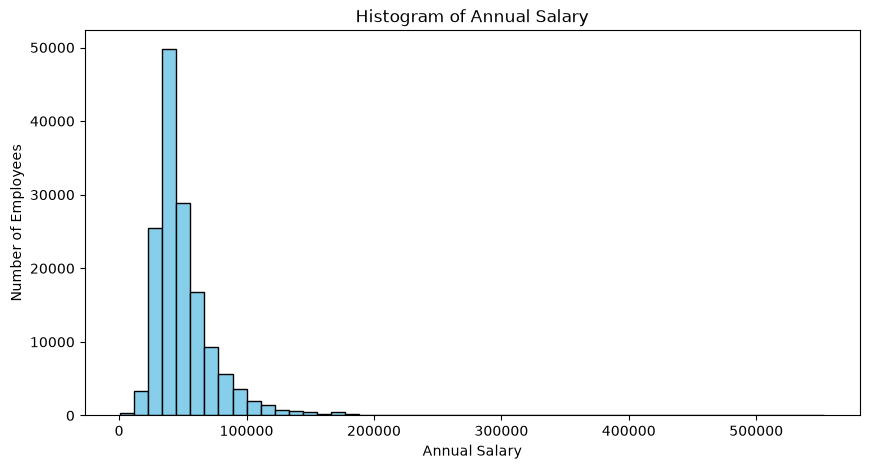

In [13]:
plt.figure(figsize=(10,5))
plt.hist(df['ANNUAL'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Annual Salary')
plt.xlabel('Annual Salary')
plt.ylabel('Number of Employees')
plt.show()

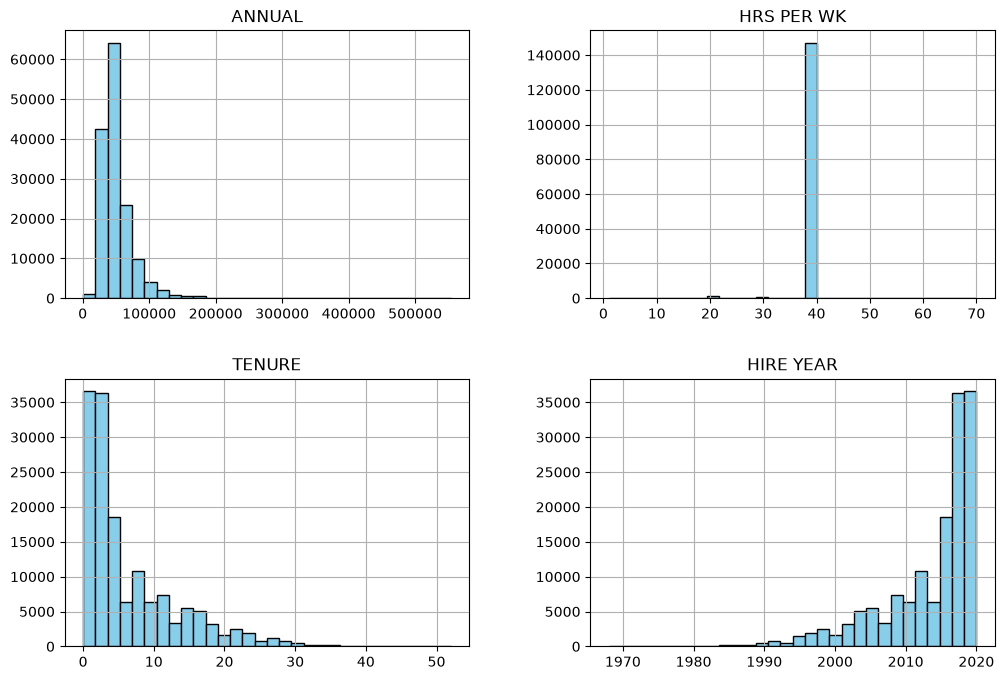

In [14]:
df[['ANNUAL', 'HRS PER WK', 'TENURE', 'HIRE YEAR']].hist(figsize=(12,8), bins=30, color='skyblue', edgecolor='black')
plt.show()

**Insights:** Annual salary is right-skewed. Most employees earn between 30,000 dollars and 60,000 dollars, and a few earn much more. Almost everyone works 40 hours a week, and most employees were hired after 2015.

## 3. Relational Plots

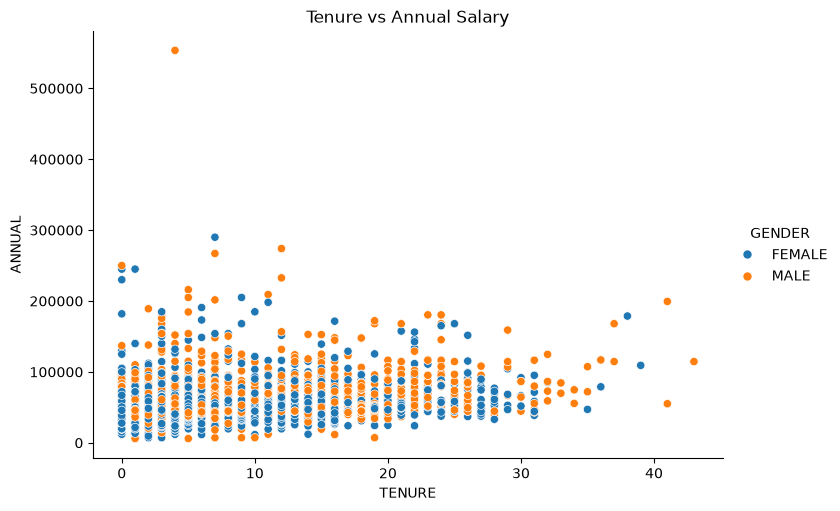

In [15]:
sns.relplot(data=df.sample(5000, random_state=1), x='TENURE', y='ANNUAL', hue='GENDER', height=5, aspect=1.5)
plt.title('Tenure vs Annual Salary')
plt.show()

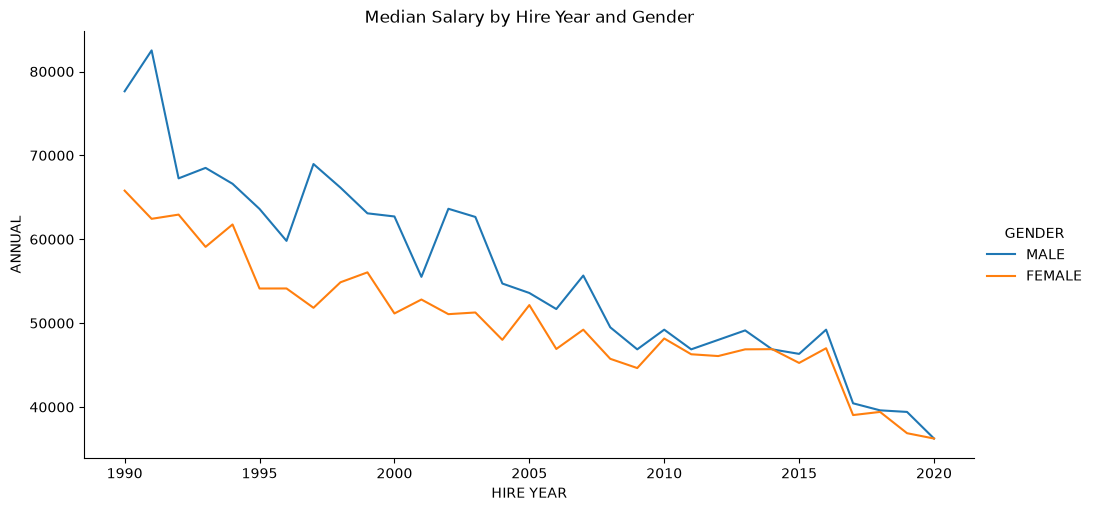

In [16]:
sns.relplot(data=df[df['HIRE YEAR'] >= 1990], x='HIRE YEAR', y='ANNUAL', hue='GENDER', kind='line',
            estimator='median', errorbar=None, height=5, aspect=2)
plt.title('Median Salary by Hire Year and Gender')
plt.show()

**Insights:** Salary generally goes up with tenure, but the spread is large because job title matters a lot. Men have a higher median salary than women in most hire years, especially among employees hired a long time ago.

## 4. Pair Plot (Multivariate Analysis)

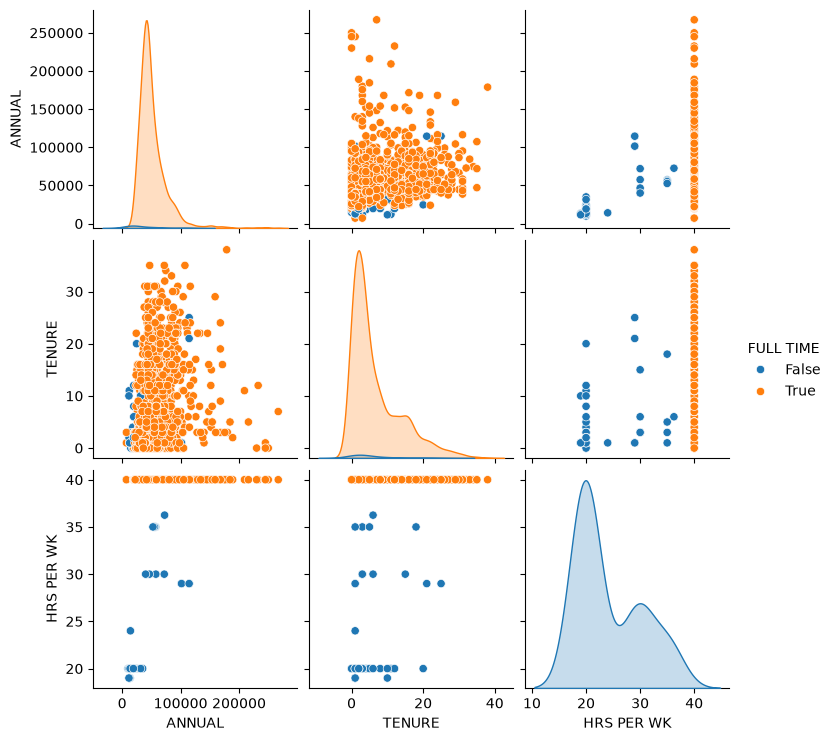

In [17]:
sns.pairplot(df[['ANNUAL', 'TENURE', 'HRS PER WK', 'FULL TIME']].sample(2000, random_state=1), hue='FULL TIME')
plt.show()

**Insights:** None of the numeric columns alone has a strong straight-line relationship with salary. Part-time employees work fewer hours and earn less. This tells us categorical columns like job title and agency are important.

## 5. Data Preprocessing
### Boxplot

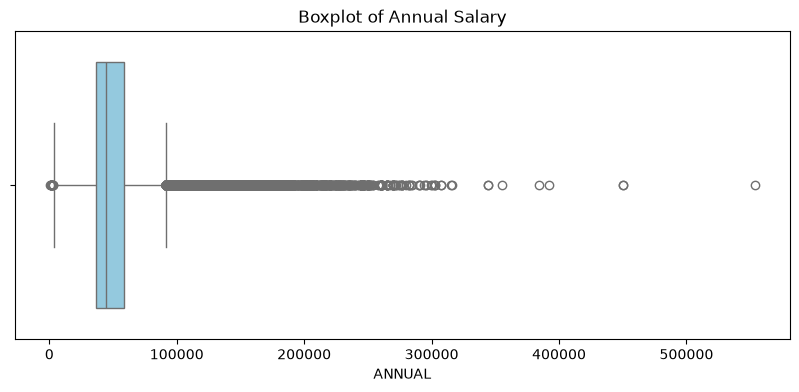

In [18]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df['ANNUAL'], color='skyblue')
plt.title('Boxplot of Annual Salary')
plt.show()

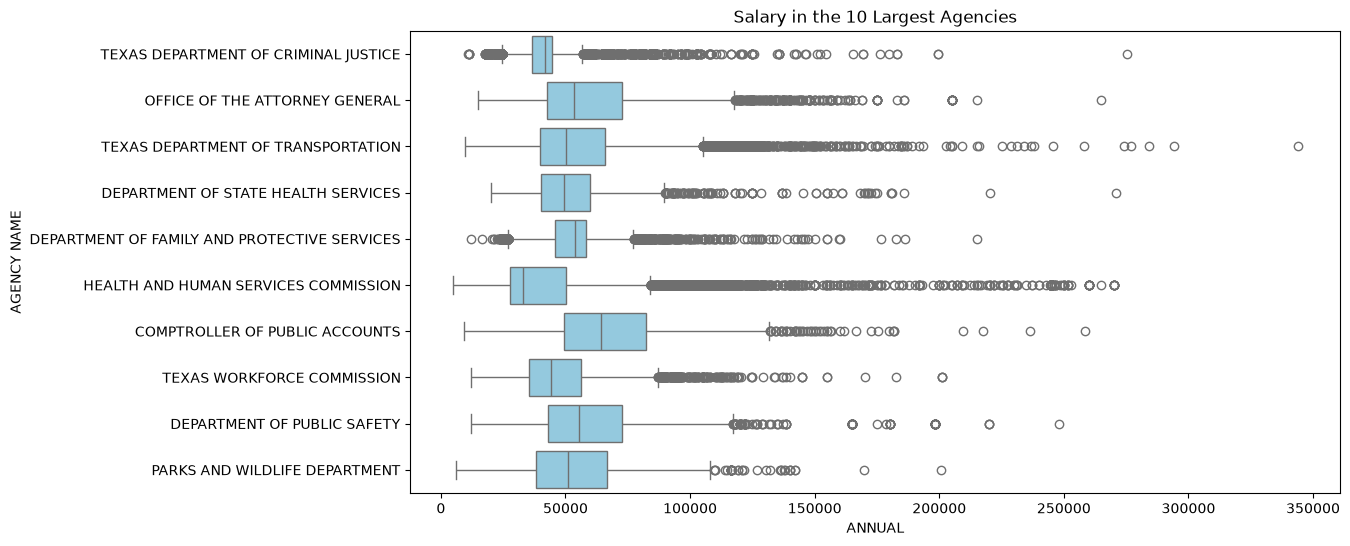

In [19]:
top_agencies = df['AGENCY NAME'].value_counts().head(10).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df[df['AGENCY NAME'].isin(top_agencies)], x='ANNUAL', y='AGENCY NAME', color='skyblue')
plt.title('Salary in the 10 Largest Agencies')
plt.show()

In [20]:
# find outliers with the IQR method
Q1 = df['ANNUAL'].quantile(0.25)
Q3 = df['ANNUAL'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print('Lower limit:', lower)
print('Upper limit:', upper)
print('Number of high outliers:', (df['ANNUAL'] > upper).sum())
print('Number of low outliers:', (df['ANNUAL'] < lower).sum())

Lower limit: 3010.6200000000026
Upper limit: 91617.18
Number of high outliers: 9018
Number of low outliers: 13


The outliers are real salaries (directors, judges, investment officers), not mistakes, so we **keep them** and look at them in Task 3.

### Line Plot

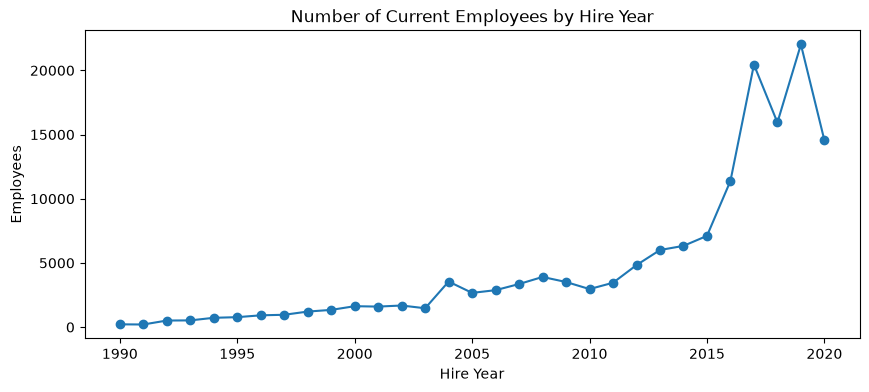

In [21]:
count_by_year = df[df['HIRE YEAR'] >= 1990].groupby('HIRE YEAR')['ANNUAL'].count()
plt.figure(figsize=(10,4))
plt.plot(count_by_year.index, count_by_year.values, marker='o')
plt.title('Number of Current Employees by Hire Year')
plt.xlabel('Hire Year')
plt.ylabel('Employees')
plt.show()

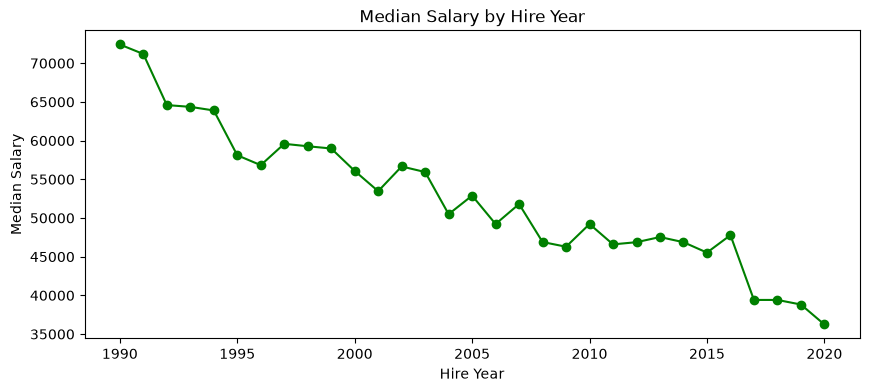

In [22]:
salary_by_year = df[df['HIRE YEAR'] >= 1990].groupby('HIRE YEAR')['ANNUAL'].median()
plt.figure(figsize=(10,4))
plt.plot(salary_by_year.index, salary_by_year.values, marker='o', color='green')
plt.title('Median Salary by Hire Year')
plt.xlabel('Hire Year')
plt.ylabel('Median Salary')
plt.show()

### Barplot

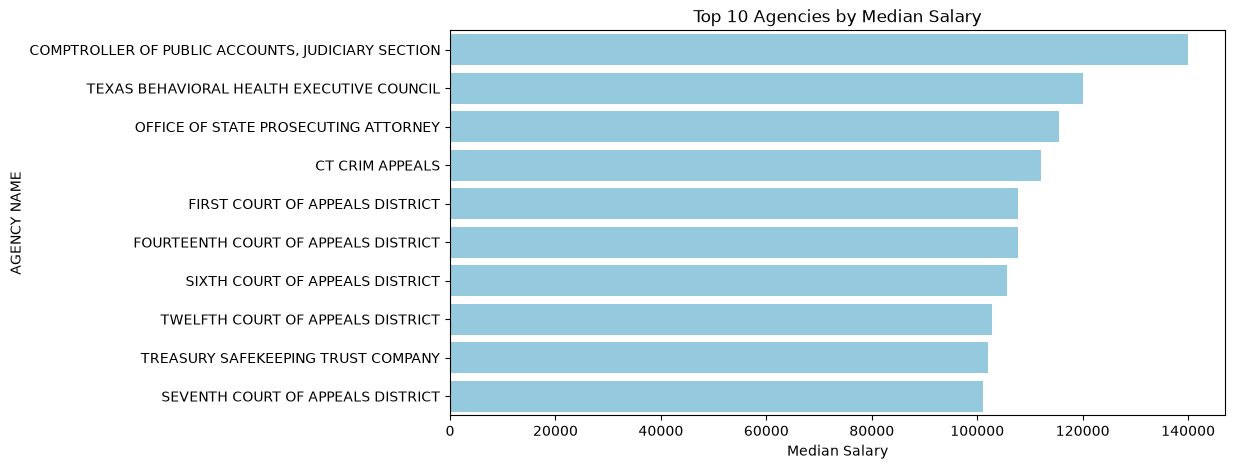

In [23]:
agency_salary = df.groupby('AGENCY NAME')['ANNUAL'].median().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=agency_salary.values, y=agency_salary.index, color='skyblue')
plt.title('Top 10 Agencies by Median Salary')
plt.xlabel('Median Salary')
plt.show()

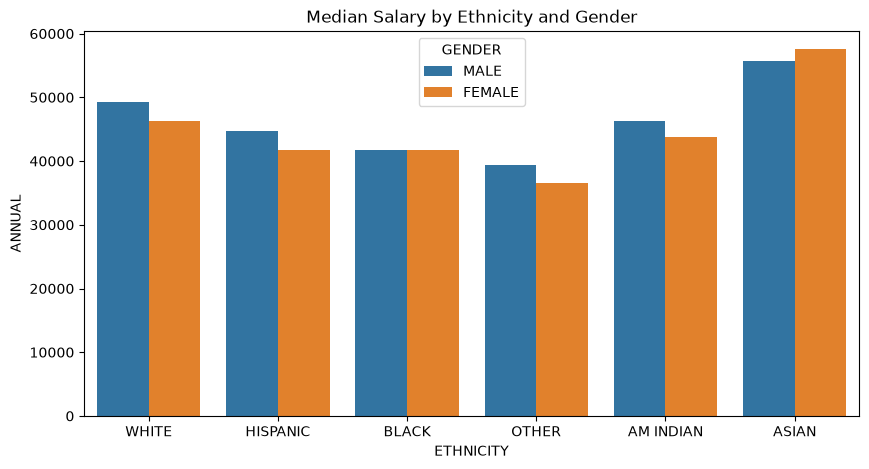

In [24]:
plt.figure(figsize=(10,5))
sns.barplot(data=df, x='ETHNICITY', y='ANNUAL', hue='GENDER', estimator=np.median, errorbar=None)
plt.title('Median Salary by Ethnicity and Gender')
plt.show()

### Encoding
Machine learning models need numbers, so we convert the text columns into numbers with `LabelEncoder`.

In [25]:
from sklearn.preprocessing import LabelEncoder

data = df.copy()
le = LabelEncoder()
for col in ['AGENCY NAME', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS']:
    data[col] = le.fit_transform(data[col])
data['FULL TIME'] = data['FULL TIME'].astype(int)
data['MANAGER'] = data['MANAGER'].astype(int)
data.head()

,AGENCY NAME,CLASS TITLE,ETHNICITY,GENDER,STATUS,HRS PER WK,MONTHLY,ANNUAL,HIRE YEAR,TENURE,FULL TIME,MANAGER
0,17,711,5,1,8,29.0,9545.82,114549.84,1988,32,0,0
1,48,560,5,1,4,4.0,1404.77,16857.24,2015,5,0,0
2,17,711,5,1,8,29.0,9545.82,114549.84,2020,0,0,0
3,48,560,5,1,4,4.0,1404.77,16857.24,2018,2,0,0
4,88,292,3,0,0,40.0,3284.27,39411.24,2020,0,1,0


## 6. Feature Selection & Heat Map

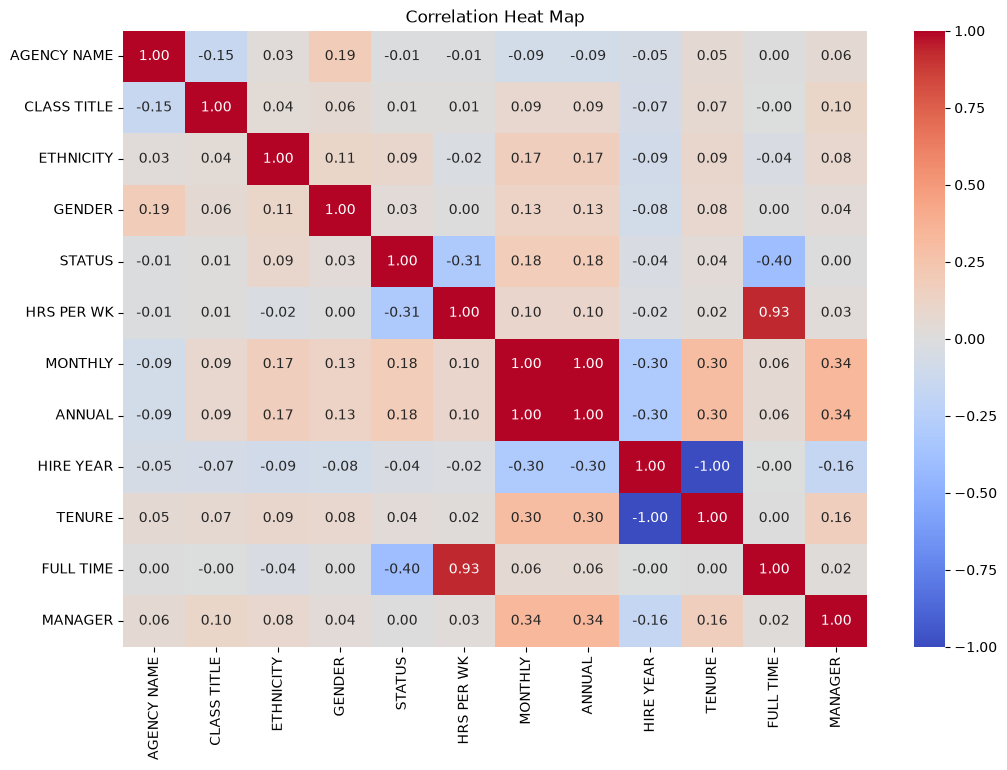

In [26]:
plt.figure(figsize=(12,8))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.show()

In [27]:
data.corr()['ANNUAL'].sort_values(ascending=False)

MONTHLY        1.000000
ANNUAL         1.000000
MANAGER        0.335601
TENURE         0.303984
STATUS         0.183917
ETHNICITY      0.170107
GENDER         0.129265
HRS PER WK     0.096041
CLASS TITLE    0.085747
FULL TIME      0.058382
AGENCY NAME   -0.085757
HIRE YEAR     -0.303984
Name: ANNUAL, dtype: float64

**Feature selection**
- `MONTHLY` is dropped, because it is the same as the target (`ANNUAL / 12`).
- `HIRE YEAR` is dropped, because it has a correlation of -1 with `TENURE` (same information).
- `STATUS` is dropped, because `FULL TIME` and `HRS PER WK` already show it.
- The features kept are: `CLASS TITLE`, `AGENCY NAME`, `MANAGER`, `TENURE`, `HRS PER WK`, `FULL TIME`, `GENDER`, `ETHNICITY`.

# Task 2: Predictive Model

## Which algorithm suits this data best?
We want to predict **annual salary**, which is a number, so this is a **supervised regression** problem.
- Logistic Regression and Naive Bayes are for classification, so they don't fit.
- K-Means and PCA are unsupervised, so they don't fit.
- SVM is too slow for 150,000 rows.
- Linear Regression, Decision Tree, KNN, Random Forest and Gradient Boosting can all do regression, so we try all five and compare them.

**Expected Best: Random Forest**, because salary does not follow a straight line, the data has outliers and noise, and Random Forest handles both well.

In [28]:
from sklearn.model_selection import train_test_split

X = data[['CLASS TITLE', 'AGENCY NAME', 'MANAGER', 'TENURE', 'HRS PER WK', 'FULL TIME', 'GENDER', 'ETHNICITY']]
y = data['ANNUAL']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(119584, 8) (29897, 8)


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'KNN': KNeighborsRegressor(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append([name, r2_score(y_train, model.predict(X_train)), r2_score(y_test, y_pred), mean_absolute_error(y_test, y_pred),
                    np.sqrt(mean_squared_error(y_test, y_pred))])

results = pd.DataFrame(results, columns=['Model', 'Train R2', 'Test R2', 'Test MAE', 'Test RMSE'])
results.sort_values('Test R2', ascending=False)

,Model,Train R2,Test R2,Test MAE,Test RMSE
3,Random Forest,0.979453,0.911791,3098.946063,7527.073826
1,Decision Tree,0.987271,0.877009,3483.415588,8888.053216
2,KNN,0.928237,0.864607,3713.168323,9325.404804
4,Gradient Boosting,0.640309,0.628045,9037.214271,15456.629073
0,Linear Regression,0.228276,0.228677,14410.863698,22258.077407


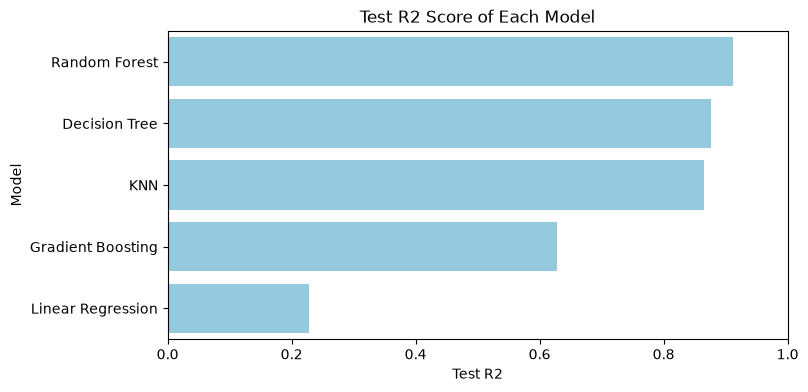

In [30]:
plt.figure(figsize=(8,4))
sns.barplot(data=results.sort_values('Test R2', ascending=False), x='Test R2', y='Model', color='skyblue')
plt.title('Test R2 Score of Each Model')
plt.xlim(0, 1)
plt.show()

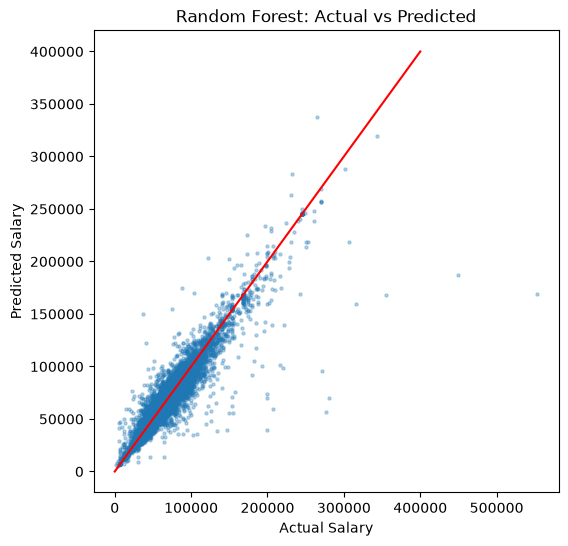

In [31]:
rf = models['Random Forest']
y_pred = rf.predict(X_test)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3, s=5)
plt.plot([0, 400000], [0, 400000], color='red')
plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.show()

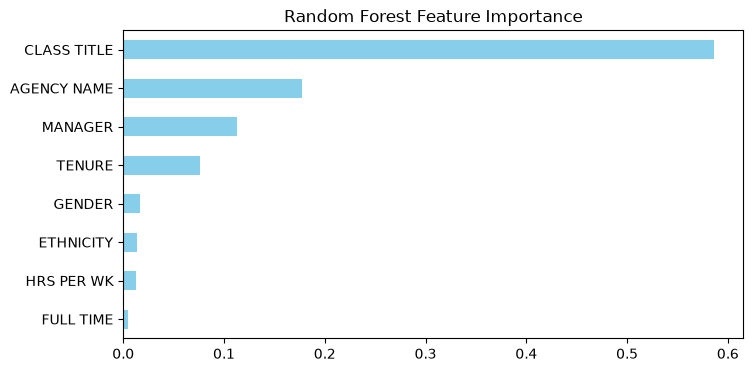

In [32]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', color='skyblue', figsize=(8,4))
plt.title('Random Forest Feature Importance')
plt.show()

**Result:** **Random Forest** is the best model, with a test R² of **0.91**. That means it explains about 91% of the variation in salary for employees it has never seen, and its average error (MAE) is about **\$3,100**. The feature importance chart shows that **job title** is by far the most important feature, followed by agency and tenure. Gender and ethnicity matter very little once the job title is known.

# Task 3: Questions

## Who are the outliers in the salaries?

In [33]:
high = df[df['ANNUAL'] > upper]
print('High outliers:', len(high))
print('Percent of employees:', round(len(high) / len(df) * 100, 1))
print('Percent of total payroll:', round(high['ANNUAL'].sum() / df['ANNUAL'].sum() * 100, 1))

High outliers: 9018
Percent of employees: 6.0
Percent of total payroll: 14.6


In [34]:
df.sort_values('ANNUAL', ascending=False)[['AGENCY NAME', 'CLASS TITLE', 'ANNUAL']].head(15)

,AGENCY NAME,CLASS TITLE,ANNUAL
83851,CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,CHIEF SCIENTIFIC OFFICER,553500.00
14793,TEACHER RETIREMENT SYSTEM,CHIEF INVESTMENT OFFICER,450000.00
144232,EMPLOYEES RETIREMENT SYSTEM,DIRECTOR OF INVESTMENTS,450000.00
15154,TEACHER RETIREMENT SYSTEM,SENIOR MANAGING DIRECTOR,391999.92
136727,TEXAS EDUCATION AGENCY,PSF CHIEF INVESTMENT OFFICER,384375.00
15041,TEACHER RETIREMENT SYSTEM,EXECUTIVE DIRECTOR,355141.44
15539,TEACHER RETIREMENT SYSTEM,SENIOR MANAGING DIRECTOR,344000.04
84769,TEXAS DEPARTMENT OF TRANSPORTATION,EXECUTIVE DIRECTOR,343999.92
144262,EMPLOYEES RETIREMENT SYSTEM,EXECUTIVE DIRECTOR FOR ERS,316116.96
15349,TEACHER RETIREMENT SYSTEM,MANAGING DIRECTOR,315000.00


In [35]:
high['AGENCY NAME'].value_counts().head(10)

AGENCY NAME
TEXAS DEPARTMENT OF TRANSPORTATION                   1257
HEALTH AND HUMAN SERVICES COMMISSION                 1209
COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION    1033
DEPARTMENT OF PUBLIC SAFETY                           613
OFFICE OF THE ATTORNEY GENERAL                        516
COMPTROLLER OF PUBLIC ACCOUNTS                        435
TEACHER RETIREMENT SYSTEM                             332
TEXAS EDUCATION AGENCY                                286
TEXAS COMMISSION ON ENVIRONMENTAL QUALITY             223
PARKS AND WILDLIFE DEPARTMENT                         186
Name: count, dtype: int64

In [36]:
high['CLASS TITLE'].value_counts().head(10)

CLASS TITLE
DIRECTOR II               646
DIRECTOR III              576
DISTRICT JUDGE, ACTIVE    472
MGR V                     461
DIRECTOR IV               371
JUDGE, RETIRED            324
DIRECTOR I                267
ATTORNEY IV               234
SYSTEMS ANALYST VI        215
DIRECTOR VI               205
Name: count, dtype: int64

In [37]:
df[df['ANNUAL'] < lower][['AGENCY NAME', 'CLASS TITLE', 'ANNUAL']]

,AGENCY NAME,CLASS TITLE,ANNUAL
141394,SENATE,LEG. SERVICE/MAINTENANCE,1039.92
141415,SENATE,LEG. SERVICE/MAINTENANCE,1039.92
141808,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,1200.00
141809,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,2400.00
141897,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,1200.00
141901,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,1200.00
142033,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,3000.00
142067,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,600.00
142114,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,1200.00
142205,HOUSE OF REPRESENTATIVES,ELECTED OFFICIALS STAFF,2521.44


## Salary Analysis: Interquartile Range (IQR) Method

**Normal Salary Range:** 3,011 dollars to 91,617 dollars  
*(Calculated using Q1 = 36,238 dollars and Q3 = 58,390 dollars)*

### Key Findings
* **High Outliers:** **9,018 employees** (6.0% of the workforce) account for **14.6%** of the state's total payroll.
* **Low Outliers:** Only **13 employees** fall below 3,011 dollars. All are House or Senate staff earning 600–3,000 dollars a year in stipend or very part-time positions.

---

### High Outlier Breakdown
These are not data errors—they represent the most senior and specialized roles in the state:

* **Key Roles:** Directors I–VI, MGR V, active and retired district judges, Attorney IVs, and Systems Analyst VIs.
* **Agency Concentration:**
  * **TxDOT:** 1,257 employees
  * **HHSC:** 1,209 employees
  * **Comptroller's Judiciary Section:** 1,033 employees *(pays the state's judges)*
  * **DPS:** 613 employees
  * **Attorney General's Office:** 516 employees

---

### Extreme Outliers & Market Competition
* **Investment Executives:** The most extreme outliers are investment staff at state pension funds. The Chief Investment Officer of the Teacher Retirement System (TRS) and the Director of Investments at ERS earn **450,000 dollars each**.
* **Highest Salary:** Belongs to the Chief Scientific Officer of the Cancer Prevention and Research Institute at **553,500 dollars**.
* **TRS Concentration:** **10 of the 15 highest-paid employees** work at TRS, reflecting compensation needed to compete with private investment firms for talent.

### Summary
The high outliers are leaders, judges, and investment staff whose pay reflects their high-level responsibilities and market rates. The low outliers are a few legislative positions that should be excluded when comparing regular salaries.

## Which departments/roles have the biggest wage gaps between managers and employees?

In [38]:
full = df[df['FULL TIME']]
print('Manager median salary :', full[full['MANAGER']]['ANNUAL'].median())
print('Employee median salary:', full[~full['MANAGER']]['ANNUAL'].median())

Manager median salary : 69731.04000000001
Employee median salary: 44520.0


In [39]:
gap = full.pivot_table(index='AGENCY NAME', columns='MANAGER', values='ANNUAL', aggfunc='median')
gap.columns = ['Employee', 'Manager']
counts = full.groupby('AGENCY NAME')['MANAGER'].agg(['sum', 'count'])
gap = gap[(counts['sum'] >= 10) & (counts['count'] - counts['sum'] >= 30)]   # agencies with at least 10 managers and 30 employees
gap['Difference'] = gap['Manager'] - gap['Employee']
gap['Ratio'] = gap['Manager'] / gap['Employee']
gap.sort_values('Ratio', ascending=False).head(10)

,Employee,Manager,Difference,Ratio
AGENCY NAME,,,,
SECRETARY OF STATE,40314.42,95768.58,55454.16,2.375542
TEACHER RETIREMENT SYSTEM,70380.00,155345.34,84965.34,2.207237
DEPARTMENT OF BANKING,78424.20,165601.32,87177.12,2.111610
TEXAS DEPARTMENT OF TRANSPORTATION,48000.00,100170.00,52170.00,2.086875
TEXAS LOTTERY COMMISSION,60124.86,124621.74,64496.88,2.072716
PUBLIC UTILITY COMMISSION OF TEXAS,66500.04,135000.12,68500.08,2.030076
EMPLOYEES RETIREMENT SYSTEM,67089.00,135567.24,68478.24,2.020707
REAL ESTATE COMMISSION,49400.04,99000.00,49599.96,2.004047
TEXAS ANIMAL HEALTH COMMISSION,37467.60,72714.96,35247.36,1.940742


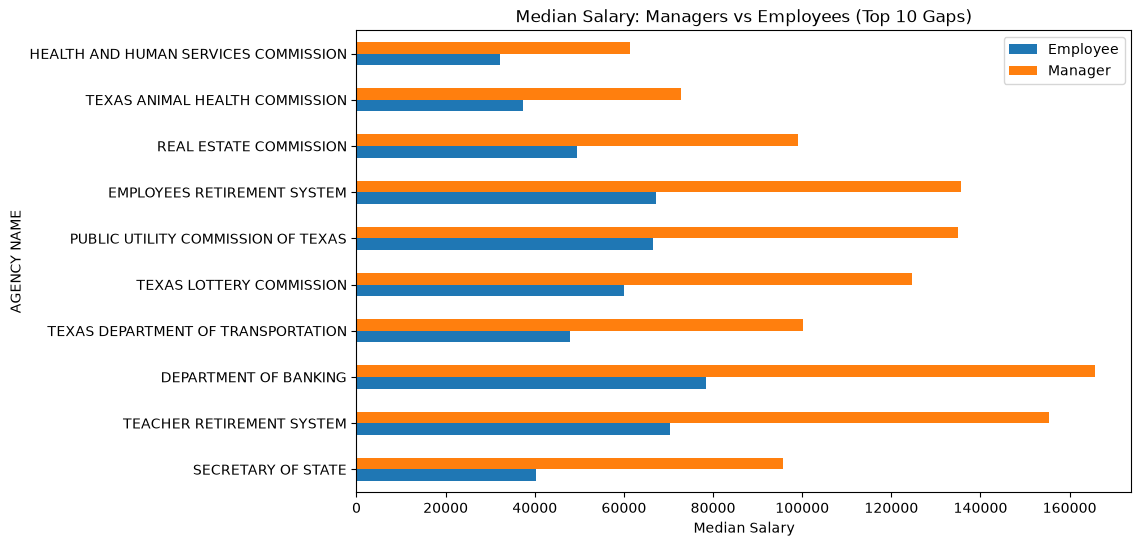

In [40]:
top_gap = gap.sort_values('Ratio', ascending=False).head(10)
top_gap[['Employee', 'Manager']].plot(kind='barh', figsize=(10,6))
plt.title('Median Salary: Managers vs Employees (Top 10 Gaps)')
plt.xlabel('Median Salary')
plt.show()

In [41]:
gap.sort_values('Difference', ascending=False).head(5)

,Employee,Manager,Difference,Ratio
AGENCY NAME,,,,
DEPARTMENT OF BANKING,78424.20,165601.32,87177.12,2.111610
TEACHER RETIREMENT SYSTEM,70380.00,155345.34,84965.34,2.207237
TREASURY SAFEKEEPING TRUST COMPANY,92604.00,168083.10,75479.10,1.815074
PUBLIC UTILITY COMMISSION OF TEXAS,66500.04,135000.12,68500.08,2.030076
EMPLOYEES RETIREMENT SYSTEM,67089.00,135567.24,68478.24,2.020707


In [42]:
gap.sort_values('Ratio').head(5)

,Employee,Manager,Difference,Ratio
AGENCY NAME,,,,
TEXAS HISTORICAL COMMISSION,53047.68,55602.00,2554.32,1.048151
TEXAS DEPARTMENT OF CRIMINAL JUSTICE,41769.24,44642.04,2872.80,1.068778
TEXAS JUVENILE JUSTICE DEPARTMENT,43592.04,54302.22,10710.18,1.245691
TEXAS MILITARY DEPARTMENT,48000.00,66055.08,18055.08,1.376148
DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES,53174.16,75000.00,21825.84,1.410460


In [43]:
# role level: directors vs front-line workers in two large agencies
hhsc = full[full['AGENCY NAME'] == 'HEALTH AND HUMAN SERVICES COMMISSION']
print('HHSC directors:', hhsc[hhsc['CLASS TITLE'].str.contains('DIRECTOR')]['ANNUAL'].median())
print('HHSC Texas Works Advisors:', hhsc[hhsc['CLASS TITLE'].str.contains('TEXAS WORKS ADVISOR')]['ANNUAL'].median())

txdot = full[full['AGENCY NAME'] == 'TEXAS DEPARTMENT OF TRANSPORTATION']
print('TxDOT directors:', txdot[txdot['CLASS TITLE'].str.contains('DIRECTOR')]['ANNUAL'].median())
print('TxDOT engineering technicians:', txdot[txdot['CLASS TITLE'].str.contains('ENGINEERING TECHNICIAN')]['ANNUAL'].median())

HHSC directors: 108723.84
HHSC Texas Works Advisors: 31587.48
TxDOT directors: 120000.0
TxDOT engineering technicians: 38400.0


## Manager vs. Non-Manager Salary Analysis

**Statewide Overview:**  
The median full-time manager earns **69,700 dollars versus 44,500 dollars for non-managers (about 1.6×)**, but the gap varies significantly between agencies.

---

### Highest Salary Ratios (Manager vs. Non-Manager)
*Among agencies with at least 10 managers and 30 employees:*

* **Secretary of State:** **2.38×** (95,800 dollars vs 40,300 dollars)
* **Teacher Retirement System (TRS):** **2.21×**
* **Department of Banking:** **2.11×**
* **TxDOT:** **2.09×**
* **Texas Lottery Commission:** **2.07×**
* **Public Utility Commission (PUC):** **2.03×**
* **Employees Retirement System (ERS):** **2.02×**

---

### Widest Dollar Gaps
Finance agencies pay higher executive salaries to compete with private banks and investment firms:

* **Department of Banking:** **87,000 dollars gap**
* **Teacher Retirement System (TRS):** **85,000 dollars gap**
* **Treasury Safekeeping Trust:** **75,000 dollars gap**

---

### Role-Level Disparities in Large Agencies
* **HHSC:** Directors earn **108,700 dollars** against **31,600 dollars** for Texas Works Advisors (**3.4× ratio**).
  * *Impact:* This affects the most people, as HHSC has over 33,000 full-time staff with a median salary of only 32,300 dollars.
* **TxDOT:** Directors earn **120,000 dollars** against **38,400 dollars** for Engineering Technicians (**3.1× ratio**).

---

### Smallest Salary Gaps
* **Texas Historical Commission:** **1.05× ratio**
* **TDCJ:** **1.07× ratio**
  * *Context:* Many TDCJ "manager" titles consist of laundry and food-service managers paid roughly the same as correctional officers.

---

### Summary
The largest manager–employee disparities occur in:
1. **Large agencies with low-paid front-line workforces** (HHSC, TxDOT)
2. **Small finance and regulatory agencies with market-priced executives** (Banking, Lottery, PUC, state retirement systems)

## Have salaries, total compensation and head-count changed over time?
The data is from one point in time (2020), so we compare employees by the **year they were hired**.

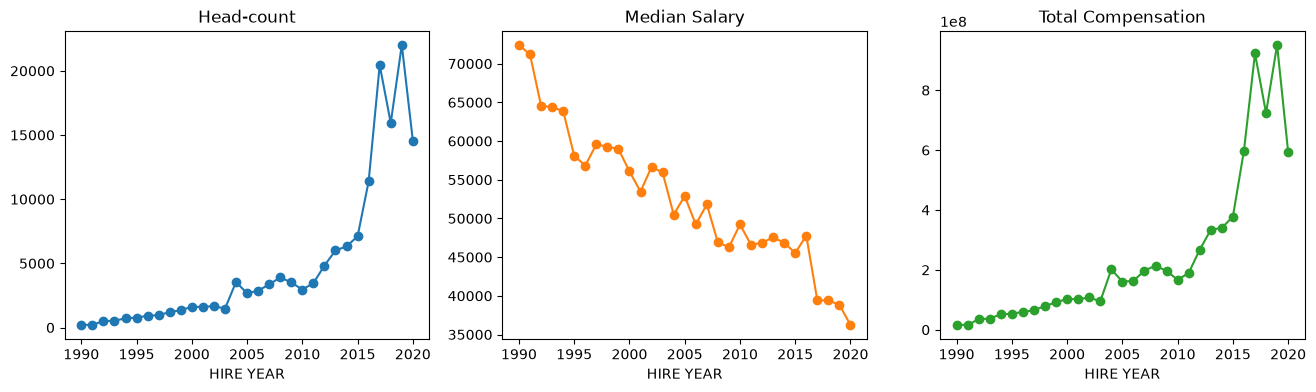

In [44]:
by_year = df[df['HIRE YEAR'] >= 1990].groupby('HIRE YEAR').agg(headcount=('ANNUAL', 'count'),
                                                                median_salary=('ANNUAL', 'median'),
                                                                total_pay=('ANNUAL', 'sum'))
by_year.plot(subplots=True, layout=(1,3), figsize=(16,4), marker='o', legend=False, title=['Head-count', 'Median Salary', 'Total Compensation'])
plt.show()

In [45]:
recent = df[df['HIRE YEAR'] >= 2016]
print('Percent of employees hired 2016-2020:', round(len(recent) / len(df) * 100, 1))
print('Percent of payroll paid to them    :', round(recent['ANNUAL'].sum() / df['ANNUAL'].sum() * 100, 1))

Percent of employees hired 2016-2020: 56.4
Percent of payroll paid to them    : 50.0


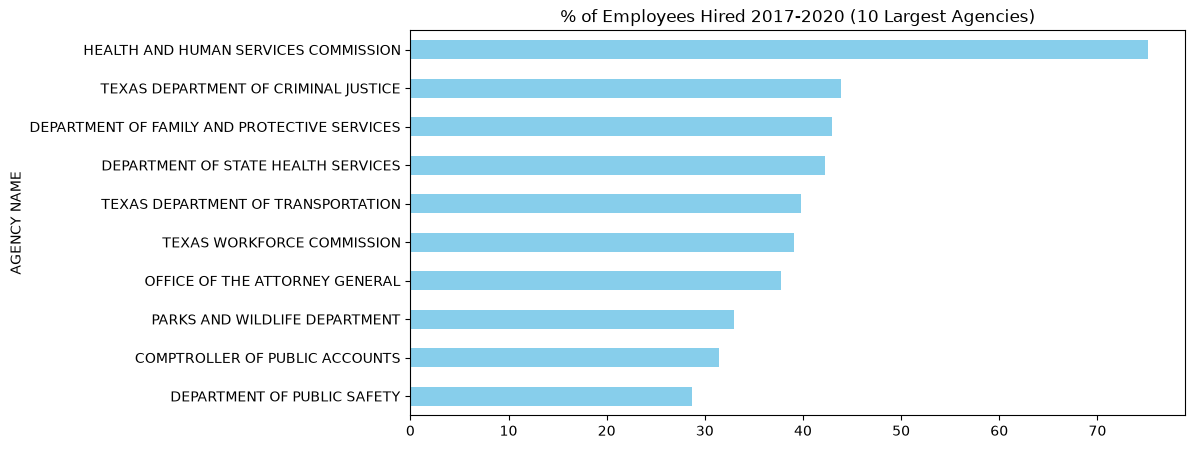

AGENCY NAME
HEALTH AND HUMAN SERVICES COMMISSION            75.201135
TEXAS DEPARTMENT OF CRIMINAL JUSTICE            43.923621
DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES    42.985383
DEPARTMENT OF STATE HEALTH SERVICES             42.249920
TEXAS DEPARTMENT OF TRANSPORTATION              39.781663
TEXAS WORKFORCE COMMISSION                      39.050075
OFFICE OF THE ATTORNEY GENERAL                  37.792804
PARKS AND WILDLIFE DEPARTMENT                   32.973856
COMPTROLLER OF PUBLIC ACCOUNTS                  31.441048
DEPARTMENT OF PUBLIC SAFETY                     28.691691
Name: HIRE YEAR, dtype: float64

In [46]:
# percent of each large agency's employees hired 2017-2020
big = df['AGENCY NAME'].value_counts().head(10).index
new_hires = df[df['AGENCY NAME'].isin(big)].groupby('AGENCY NAME')['HIRE YEAR'].apply(lambda x: (x >= 2017).mean() * 100)
new_hires.sort_values().plot(kind='barh', color='skyblue', figsize=(10,5))
plt.title('% of Employees Hired 2017-2020 (10 Largest Agencies)')
plt.show()
new_hires.sort_values(ascending=False)

In [47]:
# same job, different hire periods
roles = ['DISTRICT JUDGE, ACTIVE', 'ATTORNEY IV', 'TROOPER', 'CORREC  OFFICER IV', 'CORREC  OFFICER V',
         'ADMINISTRATIVE ASST III', 'CLERK I']
df['HIRE PERIOD'] = pd.cut(df['HIRE YEAR'], bins=[1960, 2000, 2010, 2015, 2020], labels=['before 2001', '2001-2010', '2011-2015', '2016-2020'])
role_table = df[df['FULL TIME'] & df['CLASS TITLE'].isin(roles)].pivot_table(index='CLASS TITLE', columns='HIRE PERIOD', values='ANNUAL', aggfunc='median')
role_table

HIRE PERIOD,before 2001,2001-2010,2011-2015,2016-2020
CLASS TITLE,,,,
ADMINISTRATIVE ASST III,35682.36,35160.36,35160.36,35160.36
ATTORNEY IV,106914.42,105300.00,100044.12,94500.00
CLERK I,23748.36,23748.36,23748.36,23748.36
CORREC OFFICER IV,39411.24,41769.24,41769.24,39411.24
CORREC OFFICER V,44642.04,44642.04,44642.04,43553.40
"DISTRICT JUDGE, ACTIVE",168000.00,168000.00,153999.96,139999.92
TROOPER,79323.00,72612.96,64918.92,53241.96


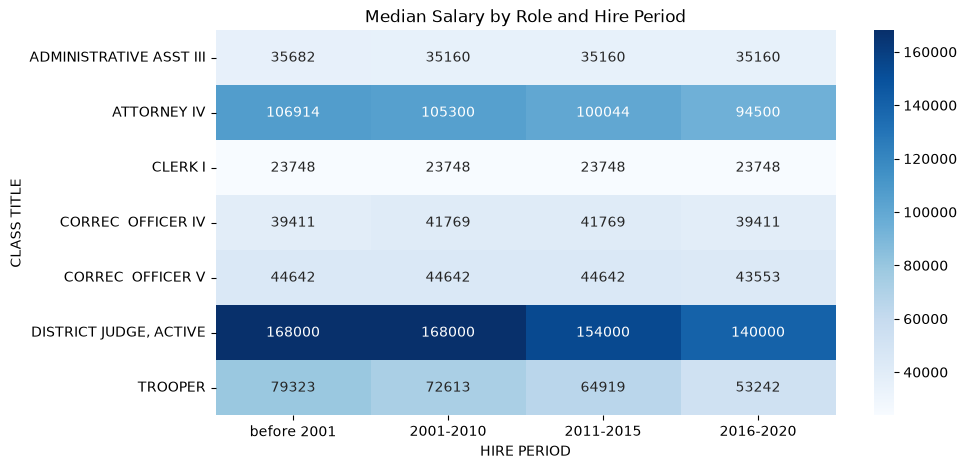

In [48]:
plt.figure(figsize=(10,5))
sns.heatmap(role_table, annot=True, fmt='.0f', cmap='Blues')
plt.title('Median Salary by Role and Hire Period')
plt.show()

In [49]:
# gender gap by hire period
gender_table = df.pivot_table(index='HIRE PERIOD', columns='GENDER', values='ANNUAL', aggfunc='median')
gender_table['Female as % of Male'] = gender_table['FEMALE'] / gender_table['MALE'] * 100
gender_table

GENDER,FEMALE,MALE,Female as % of Male
HIRE PERIOD,,,
before 2001,56232.42,67627.44,83.150301
2001-2010,48048.66,52890.00,90.846398
2011-2015,46286.76,46873.08,98.749133
2016-2020,39411.24,39524.52,99.713393


## Employee Tenure and Salary Trends Over Time

**Methodology:**  
Because the dataset is a single 2020 snapshot, change over time is analyzed by comparing employees by their hire year.

---

### Workforce Demographics & Salary Decay
* **Dominance of Recent Hires:** **56.4% of current employees joined between 2016 and 2020**, receiving **50% of total payroll**.
* **Head-Count Trend:** Employee head-count rises sharply after 2015.
* **Median Salary Drop:** Median salaries decline with each newer hire cohort:
  * **1990 Hires:** ~72,000 dollars median salary
  * **2020 Hires:** ~36,000 dollars median salary
  * *Drivers:* Long-serving staff receive promotions over time, while high-turnover entry-level positions are constantly refilled.

---

### Agency Turnover Comparison (Hired 2017–2020)
Turnover rates vary significantly across major state agencies:

* **HHSC:** **75%** of workforce hired recently *(Highest turnover)*
* **TDCJ:** **44%** of workforce hired recently
* **DFPS:** **43%** of workforce hired recently
* **DPS:** **29%** of workforce hired recently *(Most stable large agency)*

---

### Front-Line Roles vs. Seniority-Step Roles

#### 1. Flat Pay in Front-Line Roles (Inflation Erodes Real Pay)
Same-job pay across hire periods remains unchanged, meaning long-term tenure in the same role brings virtually no base pay increases:
* **Clerk I:** 23,748 dollars regardless of hire year
* **Administrative Assistant III:** ~35,000 dollars regardless of hire year
* **Correctional Officer IV & V:** 39,000 to 45,000 dollars regardless of hire year

#### 2. Clear Tenure Growth in Seniority-Step Roles
Only roles with structured seniority-based pay steps show significant pay increases over time:
* **District Judges:** **168,000 dollars** *(pre-2011 hires)* vs. **140,000 dollars** *(2016–2020 hires)*
* **State Troopers:** **79,300 dollars** *(pre-2011 hires)* vs. **53,200 dollars** *(2016–2020 hires)*
* **Attorney IVs:** **106,900 dollars** *(pre-2011 hires)* vs. **94,500 dollars** *(2016–2020 hires)*

---

### Progress on the Gender Pay Gap
The salary gap between male and female employees has steadily narrowed among newer hire cohorts:
* **Hired Before 2001:** Women earn **83%** of men's salaries
* **Hired 2001–2010:** Women earn **91%** of men's salaries
* **Hired Since 2011:** Women earn **almost 100%** of men's salaries

# Model Comparison Report

**Goal:** Predict an employee's **annual salary** (a number) from job title, agency, manager status, tenure, hours per week, full-time status, gender and ethnicity. The data has 149,481 rows, split 80% for training and 20% for testing.

| Model | Train R² | Test R² | Test MAE | Test RMSE |
|---|---|---|---|---|
| **Random Forest** | 0.979 | **0.912** | **\$3,099** | **\$7,527** |
| Decision Tree | 0.987 | 0.877 | \$3,483 | \$8,888 |
| KNN | 0.928 | 0.865 | \$3,713 | \$9,325 |
| Gradient Boosting | 0.640 | 0.628 | \$9,037 | \$15,457 |
| Linear Regression | 0.228 | 0.229 | \$14,411 | \$22,258 |

*R² = how much of the salary variation the model explains (1.0 is perfect). MAE = average error in dollars. RMSE = error that penalises big misses more.*

**How each model performed**
- **Linear Regression (R² 0.23):** the weakest model. It assumes a straight-line relationship, but job titles are label-encoded as numbers (e.g., title #500 is not "more" than title #400), so a straight line can't use them. Salary also depends on combinations of features (title + agency), which a linear model can't capture.
- **Gradient Boosting (R² 0.63):** with default settings (100 small trees, depth 3) it is underfitting. It needs more trees and deeper trees, so it would improve with tuning, but that adds training time.
- **KNN (R² 0.86):** works reasonably well, but it is slow at prediction time because it compares every new employee with all 120,000 training rows. It is also sensitive to feature scale.
- **Decision Tree (R² 0.88):** good, but its train R² (0.99) is much higher than its test R² (0.88), which shows **overfitting**: it memorises the training data.
- **Random Forest (R² 0.91):** the best on every test metric. It averages many decision trees, which reduces the overfitting of a single tree and handles outliers and non-linear patterns well.

**Recommended Model for Production: Random Forest**
1. It has the highest accuracy (R² 0.91) and the lowest errors (MAE about \$3,100).
2. It handles the salary outliers and skewed data without extra transformation.
3. It needs very little tuning to perform well, and it shows which features matter most (feature importance), which is useful for explaining results to the payroll team.
4. Predictions are fast once it is trained.

# Report on Challenges Faced

| # | Challenge in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **Mostly-empty columns:** 5 columns (`duplicated`, `multiple_full_time_jobs`, `combined_multiple_jobs`, `summed_annual_salary`, `hide_from_search`) were over 99.9% null. | Dropped the columns. | With almost no values, filling them in would mean making up data. They are publisher flags, not payroll information. |
| 2 | **Columns with no analytical value:** names, middle initial and state ID number; `AGENCY` and `CLASS CODE` were codes that repeat `AGENCY NAME` and `CLASS TITLE`. | Dropped the columns. | Names and IDs are unique to each person and can't help predict salary (and are personal data). Duplicate code columns add nothing new. |
| 3 | **`HRLY RATE` was 0 for about 99% of rows.** | Dropped the column. | It only has values for hourly workers, so it has no information for almost everyone else. |
| 4 | **Data leakage:** `MONTHLY` is exactly `ANNUAL / 12`. | Removed it from the model features (confirmed with the heat map, correlation = 1.0). | If we kept it, the model would just "read the answer," giving a fake perfect score. |
| 5 | **Extra spaces in text values** (e.g., `'WHITE          '`). | Used `.str.strip()`. | Without it, the same category could be counted as two different values, and filtering by name would fail. |
| 6 | **Two-digit years in `EMPLOY DATE`:** `'68'` was read as 2068 instead of 1968. | Converted to a date, then subtracted 100 from any year after 2020. Created `HIRE YEAR` and `TENURE`. | The data is from 2020, so no one could have been hired in the future. Tenure is a more useful number than a raw date. |
| 7 | **Redundant features:** `HIRE YEAR` and `TENURE` have a correlation of -1. | Kept only `TENURE`. | Two columns with the same information don't add accuracy and make feature importance harder to read. |
| 8 | **Text (categorical) columns:** the models need numbers. | `LabelEncoder` on agency, job title, gender, ethnicity and status. | Job title has 1,422 categories and agency has 113. One-hot encoding would create more than 1,500 columns, while label encoding keeps one column each and works well with tree models. |
| 9 | **Skewed salary with many outliers** (9,018 high outliers by IQR, up to \$553,500). | Found them with the IQR method and boxplots, but **kept** them. Chose tree-based models. | The outliers are real salaries (executives, judges, investment officers), not errors. Removing them would hide the people the state most wants to understand. Tree models are not thrown off by extreme values. |
| 10 | **Many job titles and agencies; no simple straight-line pattern.** | Compared 5 algorithms and picked Random Forest. | Linear Regression scored only 0.23 because the pattern is non-linear. Random Forest captures combinations like title + agency. |
| 11 | **Overfitting:** the single Decision Tree scored 0.99 on training data but 0.88 on test data. | Used a train/test split (80/20) to measure it, and Random Forest (many trees averaged) to reduce it. | Testing on unseen data shows the true performance, and averaging trees makes predictions more stable. |
| 12 | **Large dataset (about 150,000 rows)** made some plots and models slow. | Used random samples for the scatter and pair plots. Did not use SVM. | Plotting all points makes charts unreadable and slow. SVM takes too long on this many rows. |
| 13 | **No time-series data:** the file is one snapshot from 2020, but the question asks about change over time. | Compared employees by **hire year / hire period** instead. | This is the only time information available. We noted that it shows cohort differences, not each person's salary history. |
| 14 | **No "manager" column.** | Created a `MANAGER` flag from words in the job title (Director, MGR, Manager, Supervisor, Chief, Warden, Commissioner), excluding assistants and game wardens. | Needed to compare managers with employees. Excluding "ASST" and "GAME WARDEN" avoids labelling executive assistants and game wardens as managers. |